In [ ]:
#  python -m venv myenv
# myenv\Scripts\activate

# pip install virtualenv
#  virtualenv -p python3 virtual_env

# conda create -p venv python==3.10 -y


import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
print(df.head())
print(df.shape)



data = df[['SALES', 'QUANTITYORDERED',
           'PRICEEACH', 'MSRP']].dropna()
# Feature scaling
scaler = StandardScaler()
X = scaler.fit_transform(data)
print(data.head())



wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()



kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)
print(data.head())
print(data['Cluster'].value_counts())



plt.scatter(data['SALES'], data['QUANTITYORDERED'],
            c=data['Cluster'], cmap='rainbow')
plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.title("K-Means Clustering")
plt.show()

In [3]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(df.head())
print(df.shape)

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [4]:
data = df[['SALES', 'QUANTITYORDERED',
           'PRICEEACH', 'MSRP']].dropna()

# Feature scaling
scaler = StandardScaler()
X = scaler.fit_transform(data)

print(data.head())

     SALES  QUANTITYORDERED  PRICEEACH  MSRP
0  2871.00               30      95.70    95
1  2765.90               34      81.35    95
2  3884.34               41      94.74    95
3  3746.70               45      83.26    95
4  5205.27               49     100.00    95


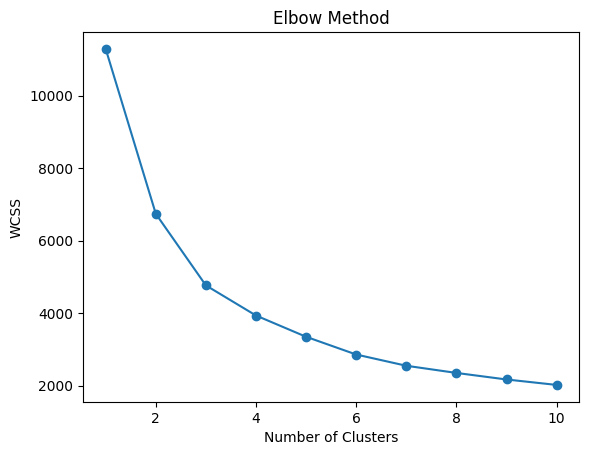

In [5]:
wcss = []

for i in range(1, 11):
    km = KMeans(n_clusters=i, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [6]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

data['Cluster'] = kmeans.fit_predict(X)

print(data.head())
print(data['Cluster'].value_counts())

     SALES  QUANTITYORDERED  PRICEEACH  MSRP  Cluster
0  2871.00               30      95.70    95        2
1  2765.90               34      81.35    95        2
2  3884.34               41      94.74    95        1
3  3746.70               45      83.26    95        1
4  5205.27               49     100.00    95        1
Cluster
2    996
0    975
1    852
Name: count, dtype: int64


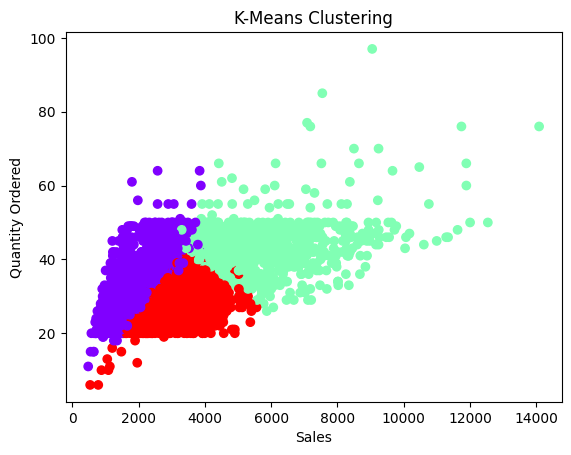

In [7]:
plt.scatter(data['SALES'], data['QUANTITYORDERED'],
            c=data['Cluster'], cmap='rainbow')

plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.title("K-Means Clustering")
plt.show()